<a href="https://colab.research.google.com/github/mlmisha/BIOCAD_TEST/blob/main/BC_test_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Imports

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, make_scorer

During the choice of the model I'd as well tested logistic regression and random forest, but gradient boosting provided best results

#Данные

In [ ]:
!wget https://life.bsc.es/pid/skempi2/database/download/skempi_v2.csv

--2025-05-02 09:21:23--  https://life.bsc.es/pid/skempi2/database/download/skempi_v2.csv
Resolving life.bsc.es (life.bsc.es)... 84.88.52.107
Connecting to life.bsc.es (life.bsc.es)|84.88.52.107|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1602208 (1.5M) [text/csv]
Saving to: ‘skempi_v2.csv’

skempi_v2.csv       100%[===================>]   1.53M  1.82MB/s    in 0.8s    

2025-05-02 09:21:25 (1.82 MB/s) - ‘skempi_v2.csv’ saved [1602208/1602208]



In [ ]:
data = pd.read_csv("/content/skempi_v2.csv",sep = ";")
data

,#Pdb,Mutation(s)_PDB,Mutation(s)_cleaned,iMutation_Location(s),Hold_out_type,Hold_out_proteins,Affinity_mut (M),Affinity_mut_parsed,Affinity_wt (M),Affinity_wt_parsed,...,koff_mut_parsed,koff_wt (s^(-1)),koff_wt_parsed,dH_mut (kcal mol^(-1)),dH_wt (kcal mol^(-1)),dS_mut (cal mol^(-1) K^(-1)),dS_wt (cal mol^(-1) K^(-1)),Notes,Method,SKEMPI version
0,1CSE_E_I,LI45G,LI38G,COR,Pr/PI,Pr/PI,5.26E-11,5.260000e-11,1.12E-12,1.120000e-12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IASP,1
1,1CSE_E_I,LI45S,LI38S,COR,Pr/PI,Pr/PI,8.33E-12,8.330000e-12,1.12E-12,1.120000e-12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IASP,1
2,1CSE_E_I,LI45P,LI38P,COR,Pr/PI,Pr/PI,1.02E-07,1.020000e-07,1.12E-12,1.120000e-12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IASP,1
3,1CSE_E_I,LI45I,LI38I,COR,Pr/PI,Pr/PI,1.72E-10,1.720000e-10,1.12E-12,1.120000e-12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IASP,1
4,1CSE_E_I,LI45D,LI38D,COR,Pr/PI,Pr/PI,1.92E-09,1.920000e-09,1.12E-12,1.120000e-12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IASP,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7080,3QIB_ABP_CD,KP9R,KP8R,COR,TCR/pMHC,"TCR/pMHC,1JCK_A_B",2.4E-04,2.400000e-04,5.5E-06,5.500000e-06,...,0.500,2.2E-02,0.022,NaN,NaN,NaN,NaN,NaN,SPR,2
7081,3QIB_ABP_CD,TP12A,TP11A,COR,TCR/pMHC,"TCR/pMHC,1JCK_A_B",>1.1E-03,1.100000e-03,5.5E-06,5.500000e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SPR,2
7082,3QIB_ABP_CD,TP12S,TP11S,COR,TCR/pMHC,"TCR/pMHC,1JCK_A_B",3.38E-05,3.380000e-05,5.5E-06,5.500000e-06,...,0.134,2.2E-02,0.022,NaN,NaN,NaN,NaN,NaN,SPR,2
7083,3QIB_ABP_CD,TP12N,TP11N,COR,TCR/pMHC,"TCR/pMHC,1JCK_A_B",4.34E-05,4.340000e-05,5.5E-06,5.500000e-06,...,0.175,2.2E-02,0.022,NaN,NaN,NaN,NaN,NaN,SPR,2


Usind data from  Affinity_mut_parsed and Affinity_wt_parsed cols it is possible
to calculate values and signs of ddG

First, dG values for mutant and WT:

$\Delta G = RTlnKd$


In [ ]:
dG_mut = 8.314*298*np.log(data["Affinity_mut_parsed"])
dG_wt = 8.314*298*np.log(data["Affinity_wt_parsed"])

Value of $\Delta \Delta G$ can be calculated from $\Delta G_{mut}$ - $\Delta G_{wt}$

In [ ]:
ddG = dG_wt - dG_mut

Add a col to the table,to keep the sign of $\Delta \Delta G$. (True/False for + и -, correspondingly)

In [ ]:
data["ddG_sign"] = ddG>0

Feature selection for training (prior to, of course...). It seems reasonable to account for mutation location (iMutation_Location), type of complex (Hold_out_type) and mutation type. Type of mutation also includes residue number and chain ID, which is without PDB structure is quite useless. That's why I'd transform the data the way they just include the type of original residue and the substitution

Text(0.5, 0, 'Число мутаций')

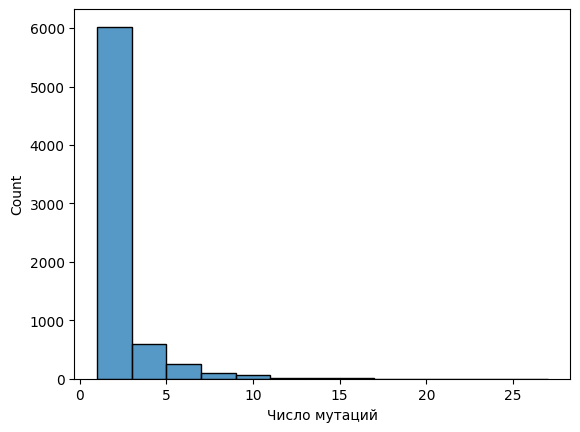

In [ ]:
sns.histplot(data = data["Mutation(s)_PDB"].str.split(",").apply(len), binwidth=2)
plt.xlabel("Число мутаций")

Leaving only the data with single mutations

Deleting the mutation location info. First, I decided to check the quality of the model when presenting this information in one column of the form "AK_DOAK_ After", for example, replacing leucine with glycine would be "LG". I assumed that this way the model would analyze the entire mutation more accurately, rather than memorizing, for example, only the final amino acid. However, the quality of the model in this case turned out to be noticeably lower. She couldn't identify the mutations that lead to increased energy accurately enough. So I still split the information about the mutation into two columns: "amino acid before" and "amino acid after"

In [ ]:
data_sep = data[data["Mutation(s)_PDB"].str.split(",").apply(len) == 1]
data_sep["Before"] = data_sep["Mutation(s)_PDB"].str[0]
data_sep["After"] = data_sep["Mutation(s)_PDB"].str[-1]

data_sep = data_sep[["Before", "After", "Hold_out_type", "iMutation_Location(s)","ddG_sign",]].dropna().reset_index()
data_sep

<ipython-input-17-d8a7c025ce3f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_sep["Before"] = data_sep["Mutation(s)_PDB"].str[0]
<ipython-input-17-d8a7c025ce3f>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_sep["After"] = data_sep["Mutation(s)_PDB"].str[-1]


,index,Before,After,Hold_out_type,iMutation_Location(s),ddG_sign
0,0,L,G,Pr/PI,COR,False
1,1,L,S,Pr/PI,COR,False
2,2,L,P,Pr/PI,COR,False
3,3,L,I,Pr/PI,COR,False
4,4,L,D,Pr/PI,COR,False
...,...,...,...,...,...,...
2411,7079,K,A,TCR/pMHC,COR,False
2412,7080,K,R,TCR/pMHC,COR,False
2413,7081,T,A,TCR/pMHC,COR,False
2414,7082,T,S,TCR/pMHC,COR,False


In [ ]:
X = data_sep.drop("ddG_sign", axis = 1)
y = data_sep["ddG_sign"]
X = pd.get_dummies(X)
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state = 11, stratify=y)

#Модель

Checking the balance of classes before train/test split

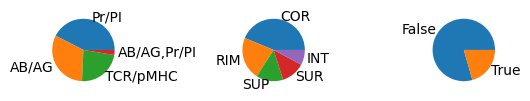

In [ ]:
fig, ax = plt.subplots(1,3)
plt.tight_layout(pad = 5)

ax[0].pie(data_1["Hold_out_type"].value_counts(), labels = data_1["Hold_out_type"].value_counts().index)
ax[1].pie(data_1["iMutation_Location(s)"].value_counts(), labels = data_1["iMutation_Location(s)"].value_counts().index)
ax[2].pie(data_1["ddG_sign"].value_counts(), labels = data_1["ddG_sign"].value_counts().index)
plt.show()

The classes of the predicted variable are highly unbalanced: there are many more mutations that reduce affinity. This will need to be taken into account when splitting. The classes in Hold_out_type and iMutation_Location(s) are also severely unbalanced, which can be dangerous.

In [ ]:
X = data_sep.drop("ddG_sign", axis = 1)
y = data_sep["ddG_sign"]

X = pd.get_dummies(X)
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state = 11, stratify=y)

In [ ]:
grad_cl_sep = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.05)

grad_cl_sep.fit(X_train, y_train)
grad_cl_sep_pred = grad_cl_sep.predict(X_test)

print(classification_report(y_test, grad_cl_sep_pred))

I was looking at the F1-score as a control metric, since the y classes are highly unbalanced and accuracy can be artificially inflated.

I tried to improve the quality by selecting hyperamaterials. I do this using GridSearchCV

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle= True, random_state= 11)

In [ ]:
params = {'max_depth': np.arange(2, 8),
         'min_samples_leaf': np.arange(2, 8)}

The number of hyperparameters is small, so I use GridSearchCV.

In [ ]:
f1 = make_scorer(f1_score , average='weighted')

In [ ]:
best_model = GridSearchCV(estimator= grad_cl_sep, param_grid= params,
                         cv= skf, verbose= True, n_jobs= -1, scoring = f1)
best_model.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=11, shuffle=True),
             estimator=RandomForestClassifier(max_depth=5, min_samples_leaf=2,
                                              n_estimators=1000),
             n_jobs=-1,
             param_grid={'max_depth': array([2, 3, 4, 5, 6, 7]),
                         'min_samples_leaf': array([2, 3, 4, 5, 6, 7])},
             scoring=make_scorer(f1_score, response_method='predict', average=weighted),
             verbose=True)

In [ ]:
best_model.best_params_

{'max_depth': np.int64(7), 'min_samples_leaf': np.int64(4)}

In [ ]:
grad_cl_sep = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.05, max_depth=7, min_samples_leaf=4)

grad_cl_sep.fit(X_train, y_train)
grad_cl_sep_pred = grad_cl_sep.predict(X_test)

print(classification_report(y_test, grad_cl_sep_pred))

              precision    recall  f1-score   support

       False       0.89      0.93      0.91       480
        True       0.66      0.54      0.60       124

    accuracy                           0.85       604
   macro avg       0.78      0.73      0.75       604
weighted avg       0.84      0.85      0.84       604



It didn't help. Well, in general, the model predicts a decrease in energy well (False), and, although much worse, it allows you to predict its increase (True).